# Pré-processamento e análise inicial do DoeFácil

Ana Júlia Alves Mota, Lauane Gabriela de Araújo Toledo e Pedro Henrique Cintra Silva.

Uma linha da base Give Food representa uma instituição. O objetivo desta entrega
é preparar esses cadastros e aplicar um agrupamento preliminar por localização.
O tratamento e o K-Means já foram executados por Lauane no Windows com Python
3.15.0. A primeira célula imprime as versões usadas ao executar este notebook.

As operações reproduzem as regras de `tratar.py` e `cluster.py`, disponíveis
no repositório do DoeFácil. Leia a explicação e execute as células em ordem.

## 1 Bibliotecas e caminhos

`Path` monta os caminhos. A pasta de trabalho pode ser a raiz do projeto ou
`mining`. As outras bibliotecas leem os dados, registram a assinatura do arquivo
e informam o ambiente da execução. `display` mostra o gráfico no notebook.


In [1]:
from pathlib import Path
from importlib.metadata import version
import hashlib
import json
import platform
import pandas as pd
from IPython.display import Image, display

PASTA = Path.cwd()
if (PASTA / "mining").is_dir():
    PASTA = PASTA / "mining"
FONTE = PASTA.parent / "givefoodbasededados.json"
saida = PASTA / "data"
saida.mkdir(exist_ok=True)

print("Python:", platform.python_version())
for nome in ["pandas", "numpy", "scikit-learn", "matplotlib"]:
    print(nome, version(nome))

Python: 3.12.14
pandas 2.2.3
numpy 2.3.5
scikit-learn 1.8.0
matplotlib 3.10.8


## 2 Carregamento e duplicações

Lemos a cópia local com UTF-8, transformamos o JSON em uma tabela e guardamos
a quantidade inicial. `drop_duplicates` mantém a primeira ocorrência de cada
`id`. O exemplo abaixo mostra apenas nome, território e rede.

In [2]:
df = pd.json_normalize(json.loads(FONTE.read_text(encoding="utf-8")))
total = len(df)
df = df.drop_duplicates(subset="id").copy()
duplicados = total - len(df)
print("Registros brutos:", total)
print("Duplicações removidas:", duplicados)
print(df[["name", "country", "network"]].head().to_string(index=False))

Registros brutos: 1023
Duplicações removidas: 0
                                 name country     network
            Aston & Nechells Foodbank England    Trussell
                 Port Talbot Foodbank   Wales    Trussell
Impakt Food Community Larder Foodbank England Independent
                    Penzance Foodbank England Independent
                         CBC Foodbank England Independent


## 3 Coordenadas e nomes

`lat_lng` traz as duas coordenadas em texto. Separamos na primeira vírgula e
convertemos cada parte em número. Conteúdos não conversíveis viram valores
ausentes. No nome, preenchemos ausências e removemos espaços nas pontas.

In [3]:
coordenadas = df["lat_lng"].str.split(",", n=1, expand=True)
df["latitude"] = pd.to_numeric(coordenadas[0], errors="coerce")
df["longitude"] = pd.to_numeric(coordenadas[1], errors="coerce")
df["name"] = df["name"].fillna("").str.strip()
print(df[["name", "latitude", "longitude"]].head().to_string(index=False))

                                 name  latitude  longitude
            Aston & Nechells Foodbank 52.497499  -1.837662
                 Port Talbot Foodbank 51.612794  -3.717996
Impakt Food Community Larder Foodbank 52.137189  -0.467974
                    Penzance Foodbank 50.128625  -5.541360
                         CBC Foodbank 52.362894  -2.056276


## 4 Filtro dos registros

As quatro condições devem ser atendidas: instituição aberta, nome preenchido,
latitude de -90 a 90 e longitude de -180 a 180. Coordenadas ausentes não passam
nos filtros de faixa. Os cinco campos selecionados são exportados para CSV.

In [4]:
validas = (df["closed"].eq(False) & df["name"].ne("")
    & df["latitude"].between(-90, 90)
    & df["longitude"].between(-180, 180))
limpo = df.loc[validas, ["id", "name", "country", "latitude", "longitude"]]
limpo.to_csv(saida / "instituicoes_tratadas.csv", index=False)
print("Registros tratados:", len(limpo))
print("Colunas:", list(limpo.columns))

Registros tratados: 1023
Colunas: ['id', 'name', 'country', 'latitude', 'longitude']


## 5 Registro do tratamento

O resumo registra a fonte, o hash SHA-256 e as contagens. O hash depende dos
bytes; finais de linha LF e CRLF podem produzir assinaturas diferentes para
registros JSON equivalentes. Nenhuma exclusão ocorreu nesta cópia, mas as
verificações e conversões foram executadas.

In [5]:
relatorio = {
    "fonte": "givefoodbasededados.json (snapshot existente no repositorio)",
    "origem": "https://www.givefood.org.uk/api/2/foodbanks/",
    "sha256": hashlib.sha256(FONTE.read_bytes()).hexdigest(),
    "registros_brutos": total,
    "duplicados_por_id": duplicados,
    "inativos_ou_invalidos": len(df) - len(limpo),
    "registros_tratados": len(limpo),
}
outputs = PASTA / "outputs"
outputs.mkdir(exist_ok=True)
(outputs / "tratamento.json").write_text(
    json.dumps(relatorio, indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps(relatorio, indent=2, ensure_ascii=False))

{
  "fonte": "givefoodbasededados.json (snapshot existente no repositorio)",
  "origem": "https://www.givefood.org.uk/api/2/foodbanks/",
  "sha256": "7068c9749ed80ffb2691e11b328a5599ea0aa20918dc4b3de566bdee4df81461",
  "registros_brutos": 1023,
  "duplicados_por_id": 0,
  "inativos_ou_invalidos": 0,
  "registros_tratados": 1023
}


## 6 Preparação para o K-Means

Lemos o CSV tratado. `StandardScaler` calcula média e desvio padrão de cada
variável e padroniza latitude e longitude. O algoritmo não recebe o nome da
rede como resposta correta. Esta é uma técnica de aprendizado não supervisionado.

In [6]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

df = pd.read_csv(PASTA / "data" / "instituicoes_tratadas.csv")
if len(df) < 4:
    raise ValueError("Precisa de pelo menos quatro instituicoes validas")
X = StandardScaler().fit_transform(df[["latitude", "longitude"]])

## 7 Formação dos grupos

Usamos três grupos, semente 42 e dez inicializações. A melhor inicialização é
escolhida pela menor inércia, não pela silhueta. `fit_predict` ajusta o modelo
e atribui um grupo a cada instituição. Os rótulos 0, 1 e 2 não são prioridades.

In [7]:
modelo = KMeans(n_clusters=3, random_state=42, n_init=10)
df["cluster"] = modelo.fit_predict(X)
grupos = int(df["cluster"].nunique())
if grupos != 3:
    raise ValueError("A base nao gerou tres grupos distintos")

## 8 Avaliação e exportação do agrupamento

Calculamos a silhueta no mesmo espaço padronizado utilizado pelo K-Means.
Ela varia de -1 a 1 e não é uma porcentagem de acerto. O CSV recebe a coluna
`cluster`, e o resumo e o gráfico são salvos em `outputs`.

As coordenadas desenhadas abaixo são as originais, em graus. As distâncias
do modelo não são quilômetros ou rotas.

{
  "tecnica": "K-Means preliminar por localizacao",
  "k": 3,
  "registros": 1023,
  "silhouette": 0.42655731672335884,
  "por_grupo": {
    "2": 503,
    "0": 370,
    "1": 150
  }
}


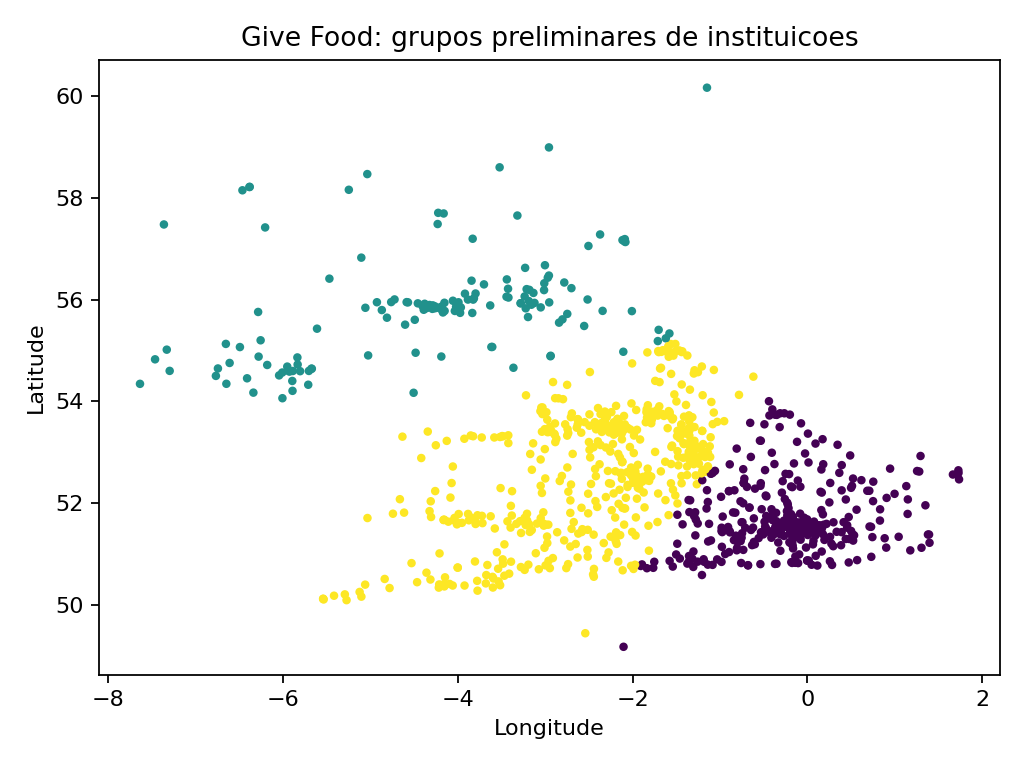

In [8]:
resumo = {
    "tecnica": "K-Means preliminar por localizacao",
    "k": 3, "registros": len(df),
    "silhouette": float(silhouette_score(X, df["cluster"])),
    "por_grupo": {str(k): int(v) for k, v in df["cluster"].value_counts().items()},
}
saida = PASTA / "outputs"
saida.mkdir(exist_ok=True)
df.to_csv(saida / "instituicoes_clusters.csv", index=False)
(saida / "resumo.json").write_text(
    json.dumps(resumo, indent=2, ensure_ascii=False), encoding="utf-8")
plt.scatter(df["longitude"], df["latitude"], c=df["cluster"], s=8, cmap="viridis")
plt.xlabel("Longitude"); plt.ylabel("Latitude")
plt.title("Give Food: grupos preliminares de instituicoes")
plt.tight_layout(); plt.savefig(saida / "clusters.png", dpi=160); plt.close()
print(json.dumps(resumo, indent=2, ensure_ascii=False))
display(Image(filename=str(saida / "clusters.png")))

## 9 Interpretação e continuidade

O tratamento preservou 1.023 cadastros. Foram formados três grupos com 370,
150 e 503 instituições, e silhueta de aproximadamente 0,4266. Zero exclusões
significa que os registros passaram nas regras aplicadas, e não que todas
as informações da fonte foram comprovadas ou atualizadas.

Os grupos descrevem localização, sem indicar demanda ou prioridade social.
Não foi demonstrado que três é a melhor quantidade de grupos. A análise é
preliminar e não calcula rotas nem prevê falta de alimentos.

Os arquivos de resultado permitem estudar e apresentar esta etapa. A integração
da mineração à API e o aprendizado supervisionado permanecem na continuidade
do semestre. Uma tarefa de estoque exigirá histórico real de entradas e saídas.

## Fontes

- Give Food API: https://www.givefood.org.uk/api/2/
- Código do projeto: https://github.com/FatecFranca/DSM-G06-PI6-2026-2
- K-Means e silhueta: https://scikit-learn.org/stable/modules/clustering.html

A organização em etapas foi estudada também no Nação Nutrida, Grupo 04 de 2026/1:
https://github.com/FatecFranca/DSM-G04-PI6-2026-1.
Os dados e as operações desta análise são os utilizados pelo DoeFácil.
